In [83]:
#Import the Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
#Load the dataset
df=pd.read_csv('https://raw.githubusercontent.com/Smarth02/KMeans/refs/heads/main/Global_Landslide_Catalog.csv')

In [84]:
#First 5 rows of the dataset
df.head()

,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy(km),landslide_category,...,admin_division_population,gazeteer_closest_point,gazeteer_distance,submitted_date,created_date,last_edited_date,longitude,latitude,Event_date,cluster
0,AGU,https://blogs.agu.org/landslideblog/2008/10/14...,684,2008-08-01 00:00:00,00:00:00,"Sigou Village, Loufan County, Shanxi Province","occurred early in morning, 11 villagers buried...","Sigou Village, Loufan County, Shanxi Province",5.0,landslide,...,0.0,Jingyang,41.02145,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,107.4500,32.5625,2008-08-01,4
1,Oregonian,http://www.oregonlive.com/news/index.ssf/2009/...,956,2009-01-02 02:00:00,02:00:00,"Lake Oswego, Oregon",Hours of heavy rain are to blame for an overni...,"Lake Oswego, Oregon",5.0,mudslide,...,36619.0,Lake Oswego,0.60342,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-122.6630,45.4200,2009-01-02,1
2,CBS News,https://www.cbsnews.com/news/dozens-missing-af...,973,2007-01-19 00:00:00,00:00:00,"San Ramon district, 195 miles northeast of the...",(CBS/AP) At least 10 people died and as many a...,"San Ramon district, 195 miles northeast of the...",10.0,landslide,...,14708.0,San Ramón,0.85548,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-75.3587,-11.1295,2007-01-19,2
3,Reuters,https://in.reuters.com/article/idINIndia-41450...,1067,2009-07-31 00:00:00,00:00:00,Dailekh district,"One person was killed in Dailekh district, pol...",Dailekh district,5.0,landslide,...,20908.0,Dailekh,0.75395,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,81.7080,28.8378,2009-07-31,4
4,The Freeman,http://www.philstar.com/cebu-news/621414/lands...,2603,2010-10-16 12:00:00,12:00:00,sitio Bakilid in barangay Lahug,Another landslide in sitio Bakilid in barangay...,sitio Bakilid in barangay Lahug,5.0,landslide,...,798634.0,Cebu City,2.02204,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,123.8978,10.3336,2010-10-16,2


In [4]:
#Converted event_date to date and time format
df['event_date']=pd.to_datetime(df['event_date'])

/tmp/ipykernel_68950/2018475273.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['event_date']=pd.to_datetime(df['event_date'])


In [85]:
#Made separate columns for date and time
df['event_time']=df['event_date'].dt.time
df['Event_date']=df['event_date'].dt.date

In [86]:
#Confirmed that new columns have been made
df.head()

,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy,landslide_category,...,admin_division_name,admin_division_population,gazeteer_closest_point,gazeteer_distance,submitted_date,created_date,last_edited_date,longitude,latitude,Event_date
0,AGU,https://blogs.agu.org/landslideblog/2008/10/14...,684,2008-08-01 00:00:00,00:00:00,"Sigou Village, Loufan County, Shanxi Province","occurred early in morning, 11 villagers buried...","Sigou Village, Loufan County, Shanxi Province",unknown,landslide,...,Shaanxi,0.0,Jingyang,41.02145,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,107.4500,32.5625,2008-08-01
1,Oregonian,http://www.oregonlive.com/news/index.ssf/2009/...,956,2009-01-02 02:00:00,02:00:00,"Lake Oswego, Oregon",Hours of heavy rain are to blame for an overni...,"Lake Oswego, Oregon",5km,mudslide,...,Oregon,36619.0,Lake Oswego,0.60342,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-122.6630,45.4200,2009-01-02
2,CBS News,https://www.cbsnews.com/news/dozens-missing-af...,973,2007-01-19 00:00:00,00:00:00,"San Ramon district, 195 miles northeast of the...",(CBS/AP) At least 10 people died and as many a...,"San Ramon district, 195 miles northeast of the...",10km,landslide,...,Junín,14708.0,San Ramón,0.85548,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-75.3587,-11.1295,2007-01-19
3,Reuters,https://in.reuters.com/article/idINIndia-41450...,1067,2009-07-31 00:00:00,00:00:00,Dailekh district,"One person was killed in Dailekh district, pol...",Dailekh district,unknown,landslide,...,Mid Western,20908.0,Dailekh,0.75395,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,81.7080,28.8378,2009-07-31
4,The Freeman,http://www.philstar.com/cebu-news/621414/lands...,2603,2010-10-16 12:00:00,12:00:00,sitio Bakilid in barangay Lahug,Another landslide in sitio Bakilid in barangay...,sitio Bakilid in barangay Lahug,5km,landslide,...,Central Visayas,798634.0,Cebu City,2.02204,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,123.8978,10.3336,2010-10-16


,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy(km),landslide_category,...,admin_division_population,gazeteer_closest_point,gazeteer_distance,submitted_date,created_date,last_edited_date,longitude,latitude,Event_date,cluster
0,AGU,https://blogs.agu.org/landslideblog/2008/10/14...,684,2008-08-01 00:00:00,00:00:00,"Sigou Village, Loufan County, Shanxi Province","occurred early in morning, 11 villagers buried...","Sigou Village, Loufan County, Shanxi Province",5.0,landslide,...,0.0,Jingyang,41.02145,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,107.4500,32.5625,2008-08-01,4
1,Oregonian,http://www.oregonlive.com/news/index.ssf/2009/...,956,2009-01-02 02:00:00,02:00:00,"Lake Oswego, Oregon",Hours of heavy rain are to blame for an overni...,"Lake Oswego, Oregon",5.0,mudslide,...,36619.0,Lake Oswego,0.60342,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-122.6630,45.4200,2009-01-02,1
2,CBS News,https://www.cbsnews.com/news/dozens-missing-af...,973,2007-01-19 00:00:00,00:00:00,"San Ramon district, 195 miles northeast of the...",(CBS/AP) At least 10 people died and as many a...,"San Ramon district, 195 miles northeast of the...",10.0,landslide,...,14708.0,San Ramón,0.85548,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-75.3587,-11.1295,2007-01-19,2
3,Reuters,https://in.reuters.com/article/idINIndia-41450...,1067,2009-07-31 00:00:00,00:00:00,Dailekh district,"One person was killed in Dailekh district, pol...",Dailekh district,5.0,landslide,...,20908.0,Dailekh,0.75395,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,81.7080,28.8378,2009-07-31,4
4,The Freeman,http://www.philstar.com/cebu-news/621414/lands...,2603,2010-10-16 12:00:00,12:00:00,sitio Bakilid in barangay Lahug,Another landslide in sitio Bakilid in barangay...,sitio Bakilid in barangay Lahug,5.0,landslide,...,798634.0,Cebu City,2.02204,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,123.8978,10.3336,2010-10-16,2


In [87]:
#Information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11033 entries, 0 to 11032
Data columns (total 32 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   source_name                11033 non-null  object        
 1   source_link                10187 non-null  object        
 2   event_id                   11033 non-null  int64         
 3   event_date                 11033 non-null  datetime64[ns]
 4   event_time                 11033 non-null  object        
 5   event_title                11033 non-null  object        
 6   event_description          10171 non-null  object        
 7   location_description       10931 non-null  object        
 8   location_accuracy          11031 non-null  object        
 9   landslide_category         11032 non-null  object        
 10  landslide_trigger          11010 non-null  object        
 11  landslide_size             11024 non-null  object        
 12  land

In [88]:
#Statistical summary of the dataset
df.describe()

,event_id,event_date,fatality_count,injury_count,event_import_id,admin_division_population,gazeteer_distance,longitude,latitude
count,11033.000000,11033,9648.000000,5359.000000,9471.000000,9.471000e+03,9471.000000,11033.000000,11033.000000
mean,5598.953141,2013-03-12 05:19:56.432520704,3.219424,0.751819,4798.563070,1.577600e+05,11.873689,2.520441,25.881887
min,1.000000,1988-11-07 00:00:00,0.000000,0.000000,-111.167300,0.000000e+00,0.000030,-179.980766,-46.774800
25%,2785.000000,2010-11-09 00:00:00,0.000000,0.000000,2386.500000,1.963000e+03,2.363845,-107.871700,13.917600
50%,5563.000000,2013-07-12 00:00:00,0.000000,0.000000,4773.000000,7.365000e+03,6.254870,19.694600,30.534500
75%,8435.000000,2015-10-19 00:00:00,1.000000,0.000000,7189.500000,3.402100e+04,15.815610,93.948000,40.866259
max,11221.000000,2017-09-28 19:36:00,5000.000000,374.000000,9669.000000,1.269184e+07,215.448880,179.991364,72.627500
std,3249.228647,NaN,59.886178,8.458955,2789.125559,8.297345e+05,15.598228,100.908393,20.415054


,event_id,event_date,location_accuracy(km),fatality_count,event_import_id,admin_division_population,gazeteer_distance,longitude,latitude,cluster
count,9393.000000,9393,9393.000000,9393.000000,9393.000000,9.393000e+03,9393.000000,9393.000000,9393.000000,9393.000000
mean,4815.407857,2012-07-21 00:19:52.136697600,11.254658,3.038965,4809.999343,1.587847e+05,11.852614,3.384434,25.575628,2.156500
min,1.000000,1988-11-07 00:00:00,0.000000,0.000000,-111.167300,0.000000e+00,0.000030,-170.799800,-46.774800,0.000000
25%,2397.000000,2010-08-24 18:00:00,1.000000,0.000000,2393.000000,1.965000e+03,2.353910,-104.984800,13.456700,1.000000
50%,4796.000000,2012-07-06 00:00:00,5.000000,0.000000,4789.000000,7.491000e+03,6.225090,20.558500,29.955100,2.000000
75%,7227.000000,2014-12-04 00:00:00,10.000000,0.000000,7220.000000,3.439900e+04,15.715770,94.475900,41.052400,3.000000
max,9685.000000,2016-10-25 13:00:00,250.000000,5000.000000,9669.000000,1.269184e+07,215.448880,179.422100,72.627500,4.000000
std,2793.180497,NaN,16.232214,60.449031,2791.378964,8.329550e+05,15.612537,100.350876,20.440643,1.182367


In [89]:
#Count of null values
df.isnull().sum()

,0
source_name,0
source_link,846
event_id,0
event_date,0
event_time,0
event_title,0
event_description,862
location_description,102
location_accuracy,2
landslide_category,1


,0
source_name,0
source_link,838
event_id,0
event_date,0
event_time,0
event_title,0
event_description,835
location_description,85
location_accuracy(km),0
landslide_category,0


In [90]:
#Remove km from every row in location_accuracy
df['location_accuracy']=(df['location_accuracy'].astype(str).str.replace('km', '', regex=False).replace('unknown', pd.NA))

KeyError: 'location_accuracy'

In [ ]:
df['location_accuracy']=pd.to_numeric(df['location_accuracy'].replace('exact', 0), errors='coerce')

In [ ]:
#Rename location_accuracy
df=df.rename(columns={'location_accuracy': 'location_accuracy(km)'})

In [ ]:
df.head(20)

,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy(km),landslide_category,...,admin_division_name,admin_division_population,gazeteer_closest_point,gazeteer_distance,submitted_date,created_date,last_edited_date,longitude,latitude,Event_date
0,AGU,https://blogs.agu.org/landslideblog/2008/10/14...,684,2008-08-01 00:00:00,00:00:00,"Sigou Village, Loufan County, Shanxi Province","occurred early in morning, 11 villagers buried...","Sigou Village, Loufan County, Shanxi Province",NaN,landslide,...,Shaanxi,0.0,Jingyang,41.02145,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,107.450000,32.56250,2008-08-01
1,Oregonian,http://www.oregonlive.com/news/index.ssf/2009/...,956,2009-01-02 02:00:00,02:00:00,"Lake Oswego, Oregon",Hours of heavy rain are to blame for an overni...,"Lake Oswego, Oregon",5.0,mudslide,...,Oregon,36619.0,Lake Oswego,0.60342,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-122.663000,45.42000,2009-01-02
2,CBS News,https://www.cbsnews.com/news/dozens-missing-af...,973,2007-01-19 00:00:00,00:00:00,"San Ramon district, 195 miles northeast of the...",(CBS/AP) At least 10 people died and as many a...,"San Ramon district, 195 miles northeast of the...",10.0,landslide,...,Junín,14708.0,San Ramón,0.85548,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-75.358700,-11.12950,2007-01-19
3,Reuters,https://in.reuters.com/article/idINIndia-41450...,1067,2009-07-31 00:00:00,00:00:00,Dailekh district,"One person was killed in Dailekh district, pol...",Dailekh district,NaN,landslide,...,Mid Western,20908.0,Dailekh,0.75395,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,81.708000,28.83780,2009-07-31
4,The Freeman,http://www.philstar.com/cebu-news/621414/lands...,2603,2010-10-16 12:00:00,12:00:00,sitio Bakilid in barangay Lahug,Another landslide in sitio Bakilid in barangay...,sitio Bakilid in barangay Lahug,5.0,landslide,...,Central Visayas,798634.0,Cebu City,2.02204,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,123.897800,10.33360,2010-10-16
5,BusinessWorld Online,http://www.bworldonline.com/content.php?sectio...,4203,2012-02-16 00:00:00,00:00:00,"Paguite, Abuyog, Leyte",Thursday’s landslides were noted in Barangays ...,"Paguite, Abuyog, Leyte",5.0,landslide,...,Eastern Visayas,2404.0,Balinsacayao,2.28967,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,124.966800,10.70040,2012-02-16
6,The Spokesman-Review,http://www.spokesman.com/stories/2012/mar/31/f...,4290,2012-03-30 00:00:00,00:00:00,"Pend Oreille County, State Route 20 near Usk, OR","In Pend Oreille County, a mudslide on State Ro...","Pend Oreille County, State Route 20 near Usk, OR",5.0,mudslide,...,Washington,2126.0,Newport,19.97241,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-117.266500,48.27970,2012-03-30
7,Crónica Diaria,http://www.cronica.com.mx/notas/2007/320673.html,225,2007-09-02 00:00:00,00:00:00,3 killed in Acapulco,"3 killed, including 2 children when rocks fell...","calle Granjas, Ampliación Miguel de la Madrid,...",10.0,complex,...,Sinaloa,3191.0,El Limón de los Ramos,10.88351,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-107.622000,24.95310,2007-09-02
8,MagicValley.com,http://magicvalley.com/news/local/first-fires-...,236,2007-09-05 00:00:00,00:00:00,"Warm Springs Road, Idaho","5 feet deep mud, Hotshot crew was trapped whil...","Warm Springs Road, Idaho",5.0,mudslide,...,Idaho,2689.0,Ketchum,4.51471,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-114.419400,43.68460,2007-09-05
9,UPI,https://www.upi.com/Top_News/2008/11/05/China-...,873,2008-11-01 00:00:00,00:00:00,"Lincang City, Yunnan, Yunnan-Tibet No. 214 hig...",The report said heavy rainfall since Oct. 24 h...,"Lincang City, Yunnan, Yunnan-Tibet No. 214 hig...",10.0,complex,...,Yunnan,0.0,Mengmeng,55.18512,04/01/2014 12:00:00 AM,11/20/2017 03:17

In [ ]:
df['location_accuracy(km)'].isnull().sum()

np.int64(544)

In [ ]:
df['location_accuracy(km)']=pd.to_numeric(df['location_accuracy(km)'], errors='coerce')
#Replace all null values by median
df['location_accuracy(km)']=df['location_accuracy(km)'].fillna(df['location_accuracy(km)'].median())

In [ ]:
df['location_accuracy(km)'].isnull().sum()

np.int64(0)

In [ ]:
#Unique values in landslide_category
df['landslide_category'].unique()

array(['landslide', 'mudslide', 'complex', 'rock_fall', 'debris_flow',
       'riverbank_collapse', 'other', 'unknown', 'lahar',
       'snow_avalanche', 'creep', 'earth_flow', 'translational_slide',
       nan, 'topple'], dtype=object)

In [ ]:
#Remove rows with null values
df=df.dropna(subset=['landslide_category', 'landslide_trigger'])

In [ ]:
#Unique values in landslide_trigger
df['landslide_trigger'].unique()

array(['rain', 'downpour', 'monsoon', 'tropical_cyclone', 'unknown',
       'continuous_rain', 'dam_embankment_collapse',
       'no_apparent_trigger', 'other', 'leaking_pipe', 'construction',
       'snowfall_snowmelt', 'mining', 'flooding', 'earthquake',
       'freeze_thaw', 'volcano', 'vibration'], dtype=object)

In [ ]:
#Unique values in landslide_size
df['landslide_size'].unique()

array(['large', 'small', 'medium', 'unknown', 'very_large',
       'catastrophic', nan], dtype=object)

In [ ]:
#Unique values in landslide_setting
df['landslide_setting'].unique()

array(['mine', 'unknown', 'above_road', 'urban', 'natural_slope', nan,
       'engineered_slope', 'below_road', 'above_river', 'retaining_wall',
       'other', 'above_coast', 'bluff', 'burned_area', 'deforested_slope'],
      dtype=object)

In [ ]:
#Replace null values with 'unknown'
df['landslide_size']=df['landslide_size'].replace('unknown', pd.NA)

In [ ]:
df['landslide_size'].isnull().sum()

np.int64(857)

In [ ]:
#Remove rows with null values
df['landslide_size']=df['landslide_size'].dropna()

In [ ]:
#Replaced null values with 'unknown'
df['landslide_setting']=df['landslide_setting'].replace('unknown', pd.NA)

In [ ]:
df['landslide_setting'].isnull().sum()

np.int64(6353)

In [ ]:
df['fatality_count']=pd.to_numeric(df['fatality_count'], errors='coerce')
#Replace null values with median
df['fatality_count']=df['fatality_count'].fillna(df['fatality_count'].median())

In [ ]:
df.isnull().sum()

,0
source_name,0
source_link,846
event_id,0
event_date,0
event_time,0
event_title,0
event_description,862
location_description,101
location_accuracy(km),0
landslide_category,0


In [ ]:
#Unique values in landslide_size
df['landslide_size'].unique()

array(['large', 'small', 'medium', nan, 'very_large', 'catastrophic'],
      dtype=object)

In [ ]:
df['landslide_size'].value_counts(dropna=False)

,count
landslide_size,
medium,6539
small,2762
NaN,857
large,747
very_large,102
catastrophic,3


In [ ]:
#Replace null values with 'unknown'
df['landslide_size']=df['landslide_size'].replace(pd.NA, "Unknown")

In [ ]:
df['landslide_size'].value_counts()

,count
landslide_size,
medium,6539
small,2762
Unknown,857
large,747
very_large,102
catastrophic,3


In [ ]:

#Unique values in landslide_setting
df['landslide_setting'].unique()

array(['mine', <NA>, 'above_road', 'urban', 'natural_slope', nan,
       'engineered_slope', 'below_road', 'above_river', 'retaining_wall',
       'other', 'above_coast', 'bluff', 'burned_area', 'deforested_slope'],
      dtype=object)

In [ ]:
df['landslide_setting'].value_counts(dropna=False)

,count
landslide_setting,
<NA>,6291
above_road,3094
natural_slope,528
urban,264
below_road,198
mine,157
above_river,148
NaN,62
deforested_slope,53


In [ ]:

#Replace null values with 'Unknown'
df['landslide_setting']=df['landslide_setting'].fillna("Unknown")

In [ ]:
sns.histplot(df['injury_count'])
plt.xlim(0,100)

In [ ]:
#Remove column injury_count
df=df.drop(columns=['injury_count'])

In [ ]:
df.isnull().sum()

In [ ]:
#Unique values in country_name
df['country_name'].value_counts()

In [ ]:
#Remove all null rows in country_name and country_code
df=df.dropna(subset=['country_name', 'country_code'])

In [ ]:
df.isnull().sum()

In [ ]:
#Remove all rows with null values in admin_division_name and gazeteer_closest_point
df=df.dropna(subset=['admin_division_name', 'gazeteer_closest_point'])

In [ ]:
df.isnull().sum()

In [ ]:
#Number of duplicated rows in df
df.duplicated().sum()

In [ ]:
categorical_columns=['landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'country_name', 'country_code']

In [ ]:
#Count plots
for column in categorical_columns:
  plt.figure(figsize=(18, 4))
  sns.countplot(data=df, x=column)
  plt.xlabel(column)
  plt.ylabel(f'Number of training examples based on {column}')
  plt.xticks(rotation=45, ha='right')
  plt.tight_layout()
  plt.show()

In [ ]:
#Unique values
for column in categorical_columns:
  print("Unique values in", column)
  print(df[column].unique())
  print("\n\n")

In [ ]:

#Checking for any negative values
(df['location_accuracy(km)']<0).sum()

In [ ]:
#Checking for any negative values
(df['fatality_count']<0).sum()

In [50]:
pip install kmodes

In [ ]:
from kmodes.kprototypes import KPrototypes

In [ ]:

df['gazeteer_distance']=pd.to_numeric(df['gazeteer_distance'], errors='coerce')

In [ ]:
df['longitude']=pd.to_numeric(df['longitude'], errors='coerce')

In [ ]:
df['latitude']=pd.to_numeric(df['latitude'], errors='coerce')

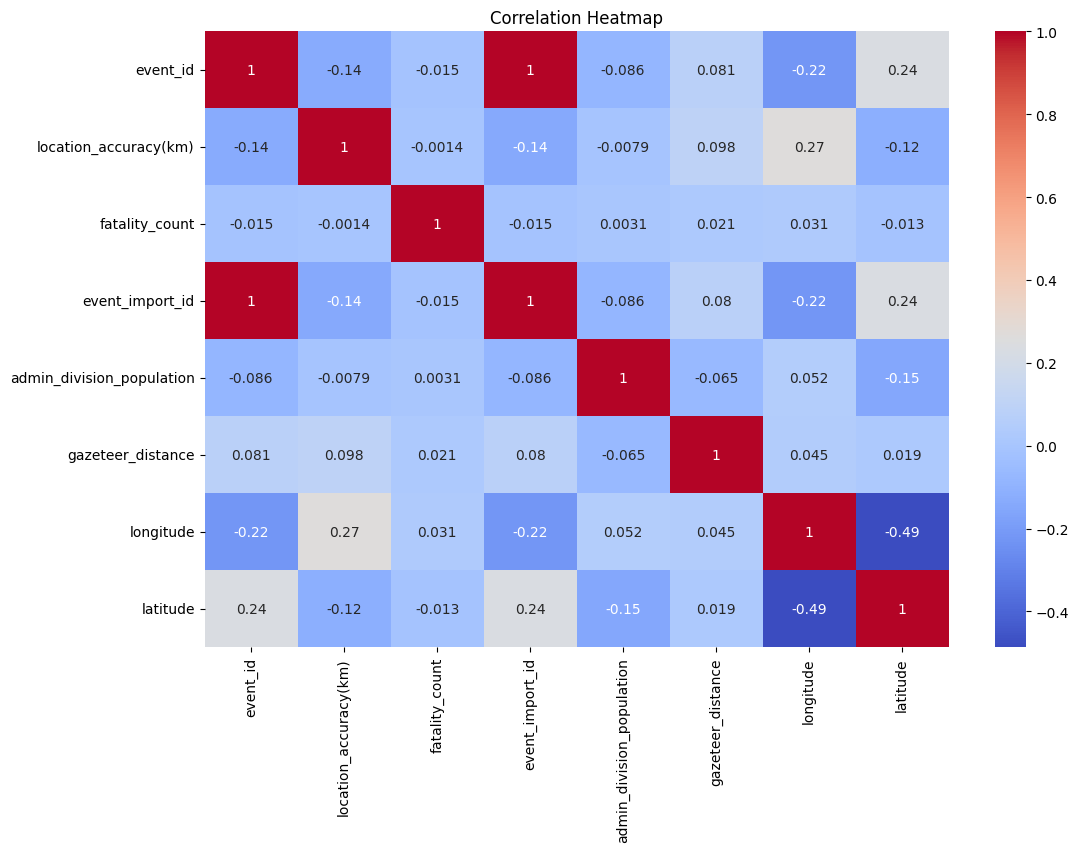

In [ ]:
#Heatmap
numerical_df=df.select_dtypes(include=np.number)
corr=numerical_df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
numerical_columns=['location_accuracy(km)', 'fatality_count', 'longitude', 'latitude']

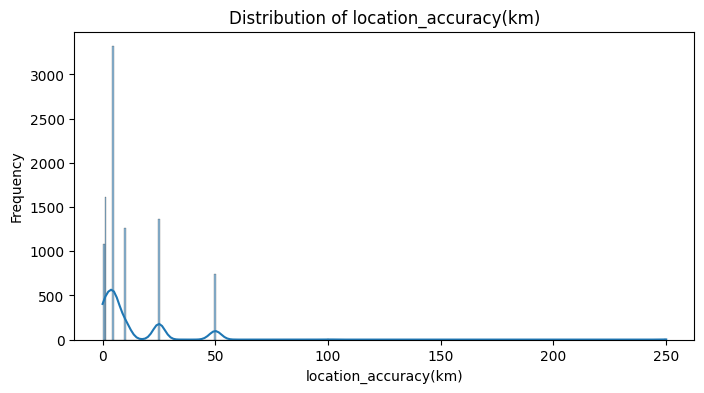

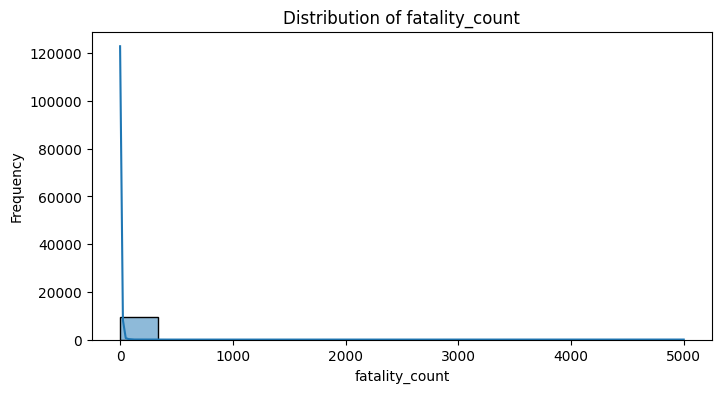

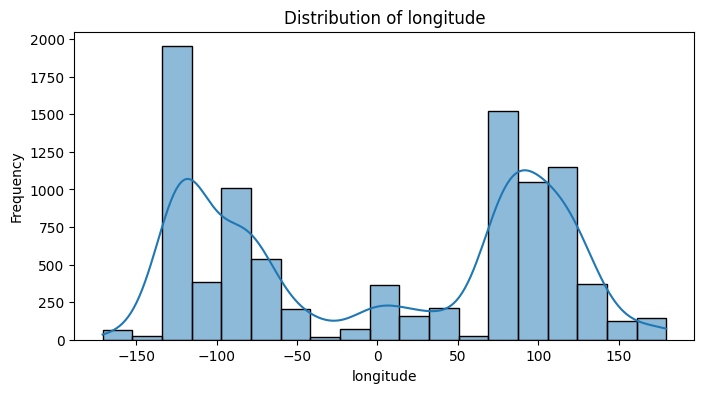

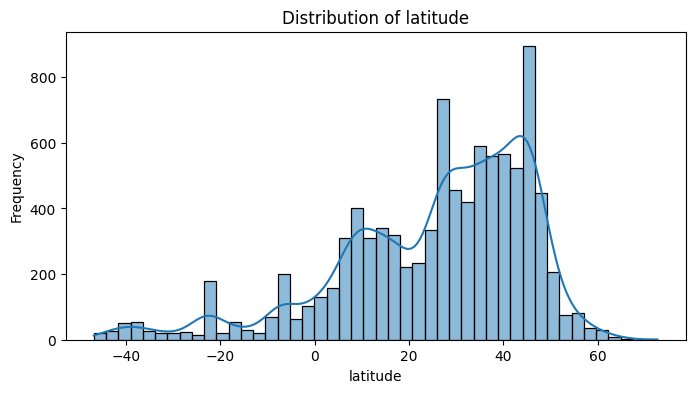

In [ ]:
#Histograms
for column in numerical_columns:
  plt.figure(figsize=(8, 4))
  sns.histplot(data=df, x=column, kde=True)
  plt.xlabel(column)
  plt.ylabel('Frequency')
  plt.title(f'Distribution of {column}')
  plt.show()

In [ ]:
df[numerical_columns].isnull().sum()

,0
location_accuracy(km),0
fatality_count,0
longitude,0
latitude,0


In [ ]:
scaler=StandardScaler()

In [ ]:
X_numerical=scaler.fit_transform(df[numerical_columns])

In [ ]:
numerical_df=pd.DataFrame(X_numerical, columns=numerical_columns, index=df.index)
X=pd.concat([numerical_df, df[categorical_columns]], axis=1)

In [ ]:
X

In [63]:
K=[2, 3, 4, 5, 6, 7, 8, 9, 10]
inertia=[]
clusters=[]
for k in K:
  kproto=KPrototypes(n_clusters=k, random_state=42, n_init=10)
  kproto.fit_predict(X, categorical=[4, 5, 6, 7, 8, 9])
  inertia.append(kproto.cost_)
  clusters.append(kproto)


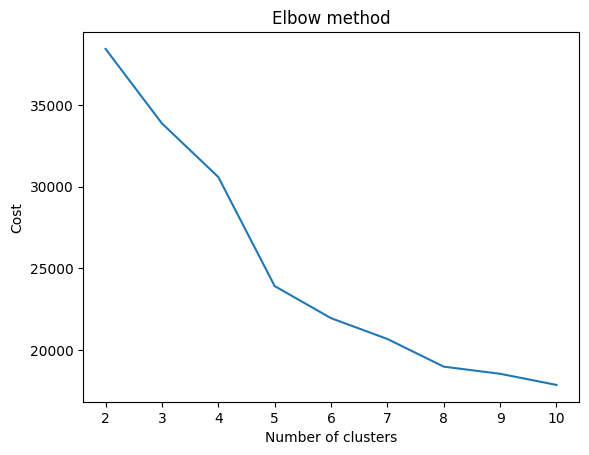

In [91]:
plt.plot(K, inertia)
plt.title("Elbow method")
plt.xlabel('Number of clusters')
plt.ylabel('Cost')
plt.show()

Clusters 1
0    4249
1    5144
Name: count, dtype: int64
0    45.235814
1    54.764186
Name: proportion, dtype: float64
Numerical Columns
         location_accuracy(km)  fatality_count  longitude   latitude
cluster                                                             
0                     5.491880        0.512591 -92.668866  39.145058
1                    16.014774        5.125778  82.725506  14.367131



Categorical columns
landslide_category

landslide_category  complex  creep  debris_flow  earth_flow  lahar  landslide  \
cluster                                                                         
0                      0.02    0.0         0.03         0.0    0.0       0.57   
1                      0.03    0.0         0.01         0.0    0.0       0.81   

landslide_category  mudslide  other  riverbank_collapse  rock_fall  \
cluster                                                              
0                       0.29   0.01                 0.0       0.07   
1       

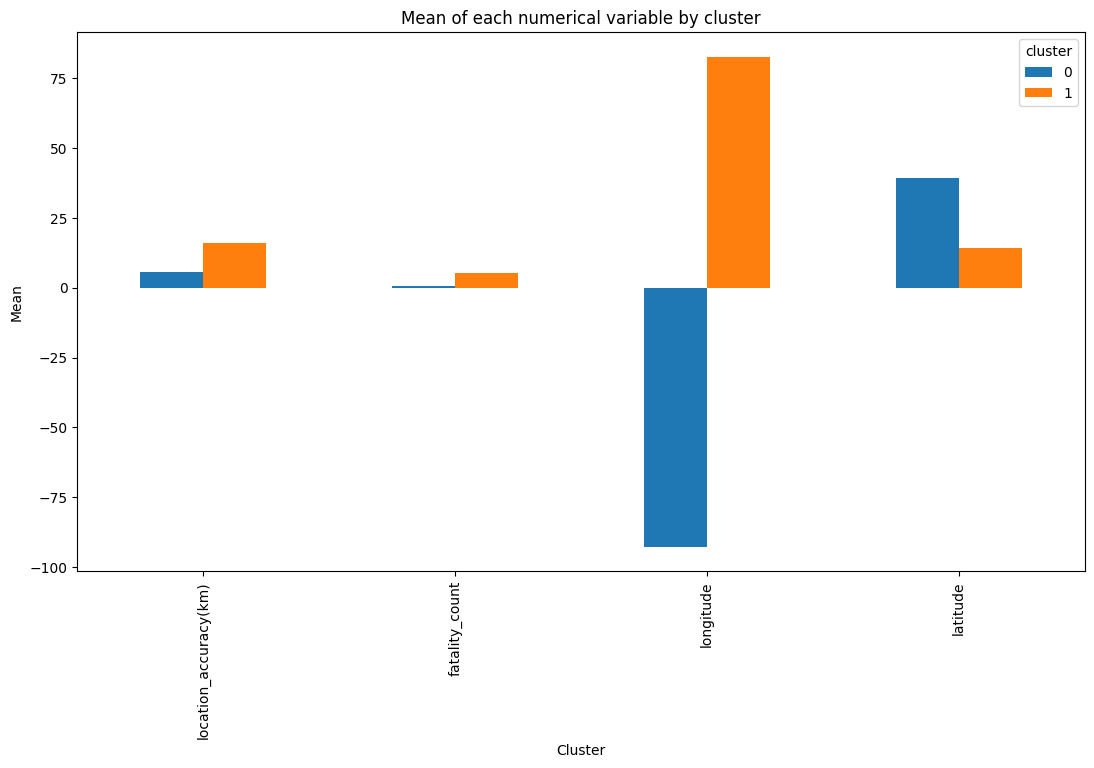

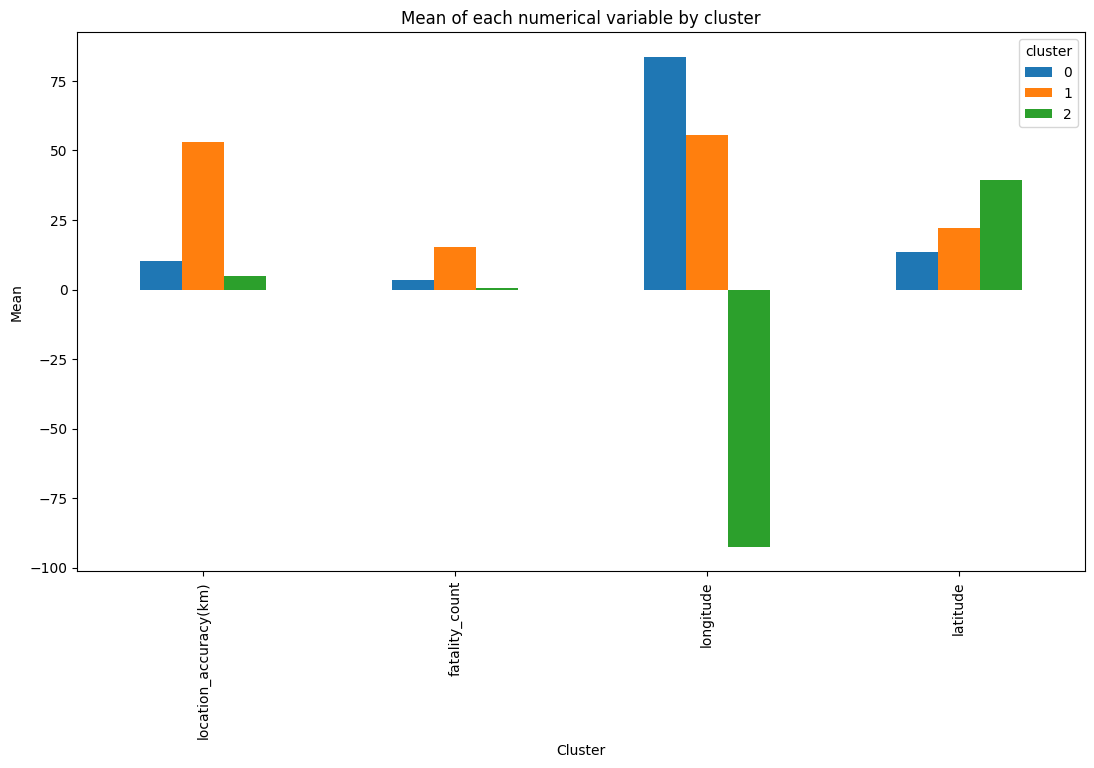

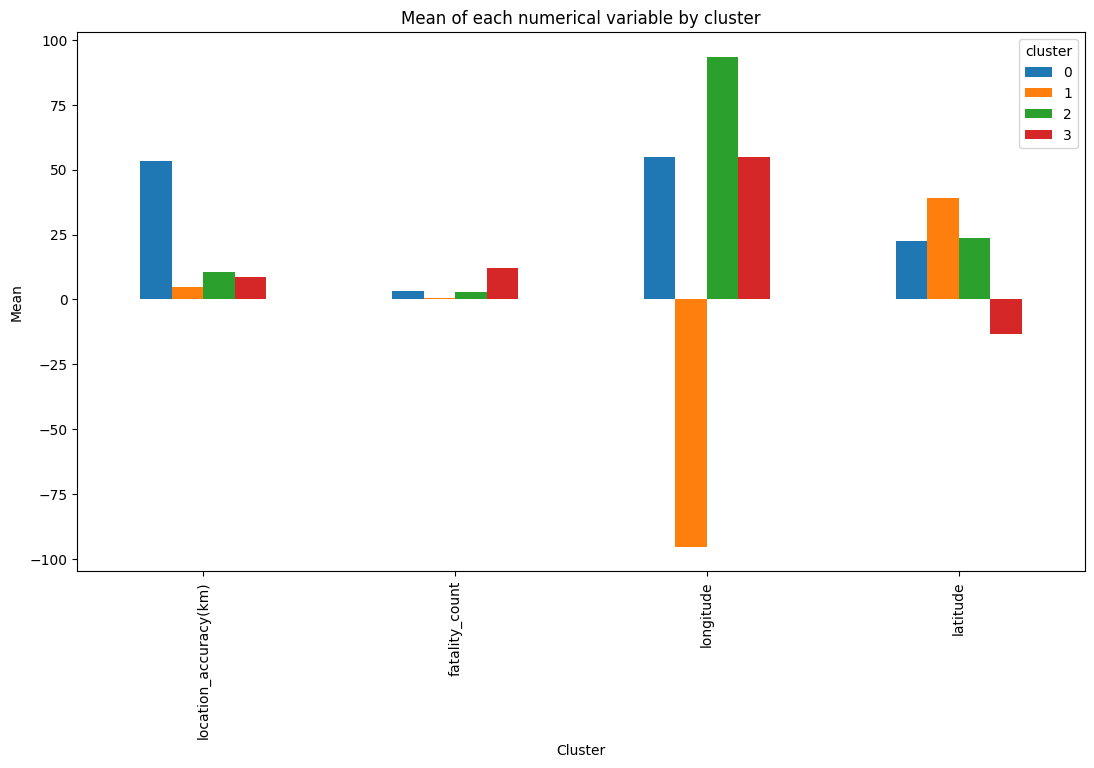

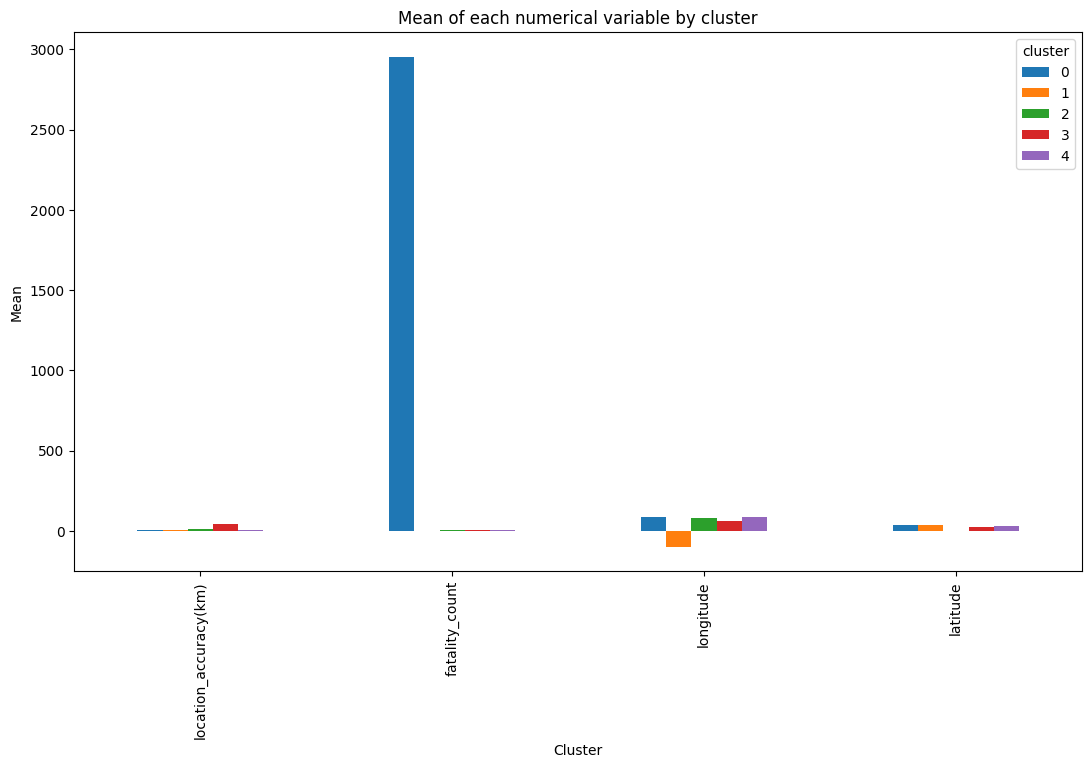

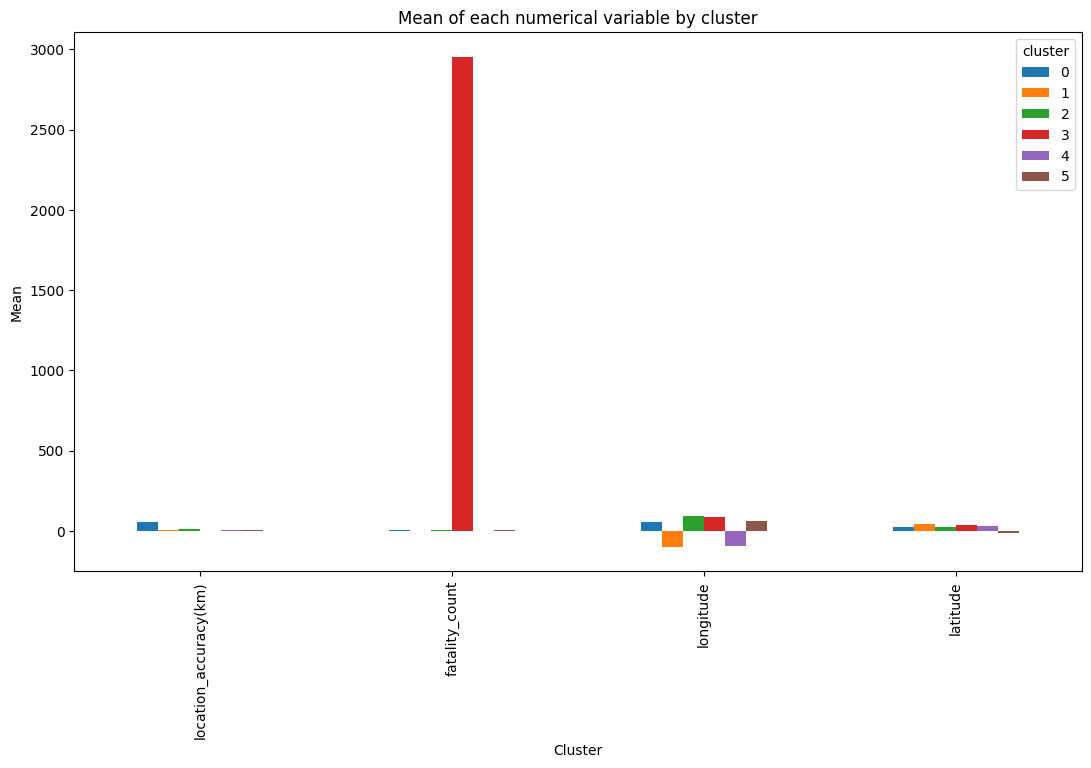

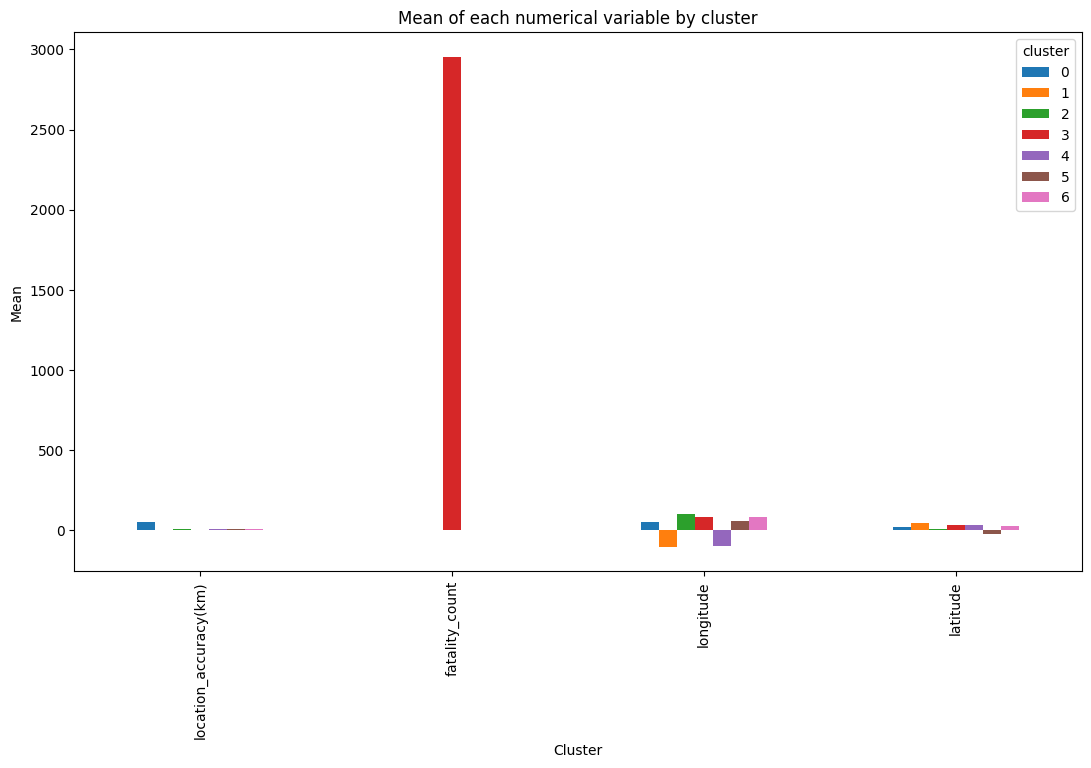

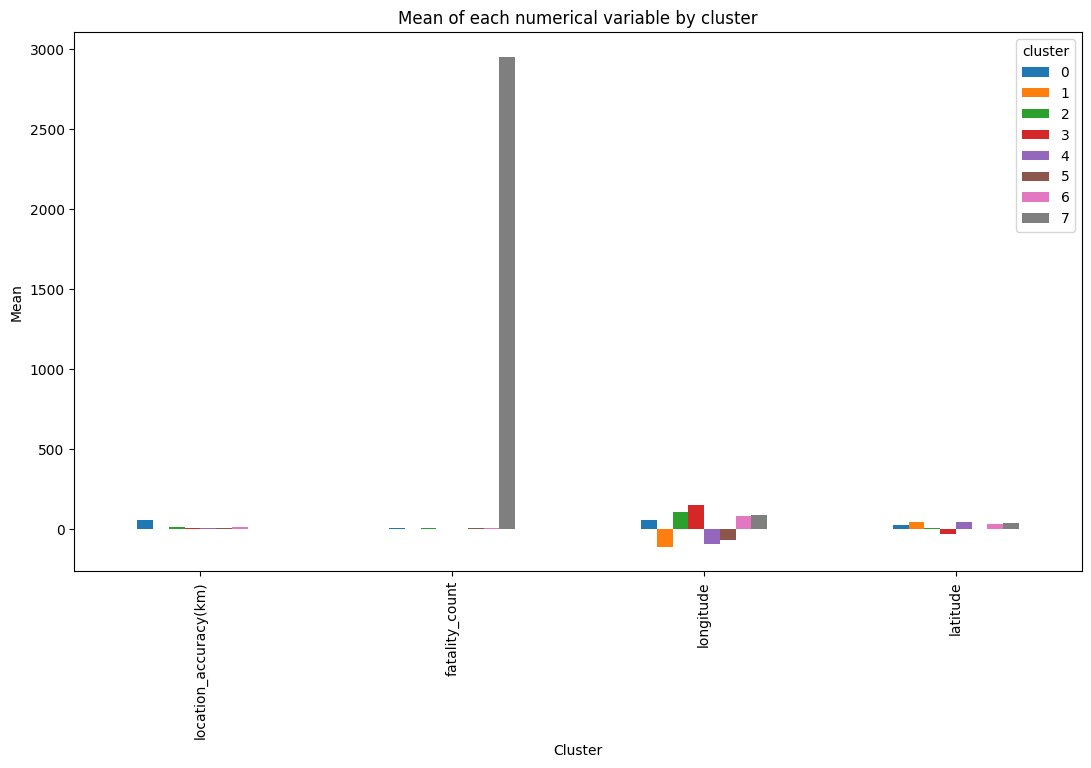

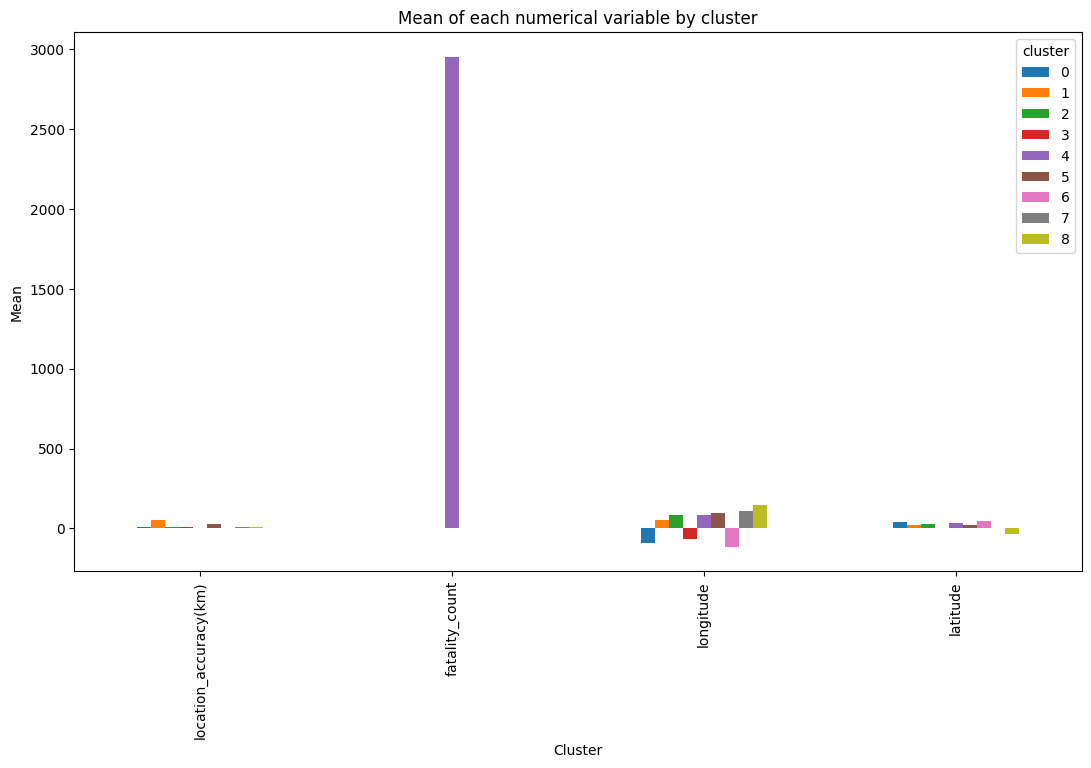

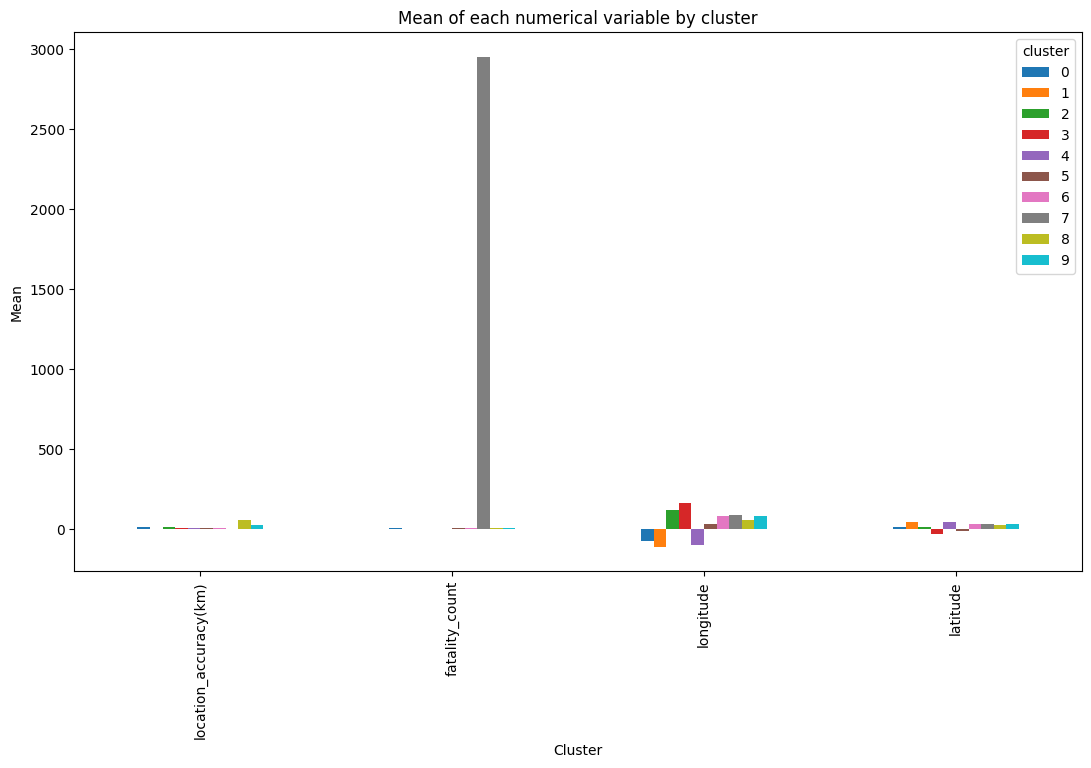

In [65]:
for cluster in clusters:
  print("Clusters", clusters.index(cluster)+1)
  data=cluster.fit_predict(X, categorical=[4, 5, 6, 7, 8, 9])
  print(pd.Series(data).value_counts().sort_index())
  cluster_percent=(pd.Series(data).value_counts(normalize=True).sort_index()*100)
  print(cluster_percent)
  temp_df=df.copy()
  temp_df['cluster']=data
  print("Numerical Columns")
  print(temp_df.groupby('cluster')[numerical_columns].mean())
  print("\n\n")
  print("Categorical columns")
  for col in categorical_columns:
    print(f"{col}\n")
    print(
        pd.crosstab(
            temp_df['cluster'],
            temp_df[col],
            normalize='index'
        ).round(2)
    )
    print("\n\n")
  cluster_means=temp_df.groupby('cluster')[numerical_columns].mean()
  cluster_means.T.plot(kind='bar', figsize=(13, 7))
  plt.ylabel('Mean')
  plt.xlabel('Cluster')
  plt.title('Mean of each numerical variable by cluster')
  print("\n\n")
  print("Cluster centeriods")
  print(cluster.cluster_centroids_)
  print("Cost", cluster.cost_)
  print("\n\n")

In [92]:
kproto=KPrototypes(
    n_clusters=5,
    n_init=10,
    random_state=42
)

In [93]:
clusters=kproto.fit_predict(X, categorical=[4, 5, 6, 7, 8, 9])

In [94]:
df['cluster']=clusters

In [95]:
#Number of rows in each cluster
df['cluster'].value_counts().sort_index()

,count
cluster,
0,3
1,3943
2,2021
3,1433
4,1993


In [96]:
print(f'Cost for the model {kproto.cost_}')

Cost for the model 23910.021148896347


In [97]:
from sklearn.metrics import adjusted_rand_score, silhouette_score

In [98]:
labels_1=KPrototypes(n_clusters=5, n_init=10, random_state=42).fit_predict(X, categorical=[4, 5, 6, 7, 8, 9])

In [99]:
labels_2=KPrototypes(n_clusters=5, n_init=4, random_state=100).fit_predict(X, categorical=[4, 5, 6, 7, 8, 9])

In [100]:
ari=adjusted_rand_score(labels_1, labels_2)

In [101]:

print("Stability ARI:", ari)

Stability ARI: 0.8847332539199472


In [102]:
pip install gower

In [103]:
import gower

In [104]:
D=gower.gower_matrix(X)

In [105]:
D_eval=D
labels=df['cluster']

In [106]:
score=silhouette_score(
    D_eval,
    labels,
    metric='precomputed'
)

In [107]:
print("Gower Silhouette score", score)

Gower Silhouette score 0.14121985
